# 04. 2호점 후보 추천

- **목적**: 매장 1곳을 운영하는 소규모 카페 브랜드의 2호점 후보 상권 3곳 선정
- **데이터 출처**
  - DB `추천_지표`: `sql/02_추천지표.sql`로 생성, 최근 12개 분기(2023년 3분기 ~ 2026년 2분기)에 커피 매출이 모두 공개된 상권
  - DB `영역`, `커피_매출`, `커피_점포` (`03_SQL적재` 출력)
  - `data/raw/임대동향 지역별 임대료(2026년2분기)_소규모 상가.csv`: 한국부동산원 상업용부동산 임대동향조사 2026년 2분기 (R-ONE)
- **출력**: `data/processed/추천_순위.csv`, `추천_깔때기.csv`, `추천_임대료.csv`
- **기준 문서**: `docs/지표_정의서.md`
- **작성일**: 2026-10-16 (출력은 2026-10-15 실행 결과)

## 결론 요약
- 분석 대상 992개 상권 → 6단계 거르기 후 84개 → 1km 일대로 묶어 순위 산정
- **추천 3곳: 공릉역(노원구, 96.1점), 대치역(강남구, 93.5점), 방이역(송파구, 92.2점)**
- 세 곳 모두 점포당 손님 2년 증가율 +53.2% ~ +90.2%, 카페 수는 2년 사이 −4.3% ~ −29.7%
- 3위 선릉역(92.3점)은 대치역과 2km 안이라 제외, 4위 방이역과 점수 차 0.1점
- 세 곳 모두 1.5km 안에 임대료 조사 상권 없음 → 실제 매물 임대료·권리금 별도 확인 필요

## 설정

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import text

sys.path.append("..")  # notebooks/에서 실행하므로 프로젝트 루트의 src를 import 경로에 추가
from src.db import get_engine
from src.viz import quarter_label, set_korean_font

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 60)
set_korean_font()

In [2]:
ENV_PATH = Path("../.env")
RAW_DIR = Path("../data/raw")
OUT_DIR = Path("../data/processed")
METRIC_SQL_PATH = Path("../sql/02_추천지표.sql")
RENT_FILE = "임대동향 지역별 임대료(2026년2분기)_소규모 상가.csv"
RECENT_START_QUARTER = "20233"  # 추천_지표와 같은 최근 12개 분기의 시작

MIN_STORES = 10              # 2년 전·최근 평균 카페 수 하한
MAX_TICKET_CHANGE_PCT = 50   # 2년 건당 금액 변화율 절댓값 상한
MIN_YOY_UP_QUARTERS = 3      # 최근 4개 분기 중 전년 같은 분기보다 손님이 많은 분기 수 하한

CLUSTER_RADIUS_M = 1000      # 걸어서 닿는 범위는 한 일대로 봄
TOP_N_CLUSTERS = 10          # TODO(확인 필요): 임대료 확인을 상위 10개 일대로 한정한 근거 없음
RENT_SEARCH_KM = 1.5         # TODO(확인 필요): 조사 상권 매칭 반경 1.5km의 근거 없음
RENT_LIMIT_RATIO = 1.5       # TODO(확인 필요): 서울 평균 1.5배 상한(원칙 4)의 출처 미기록
MIN_GAP_M = 2000             # 추천 3곳이 서로 다른 생활권이 되도록 하는 최소 거리
N_PICK = 3

In [3]:
# 임대료 조사 상권에는 좌표가 없어 이름이 같은 상권분석서비스 상권의 중심 좌표를 위치로 사용
# 테헤란로는 강남역~삼성역 구간의 가운데인 선릉역, 혜화동은 대학로(혜화역)로 대체
SURVEY_LOCATION = {
    "광화문": "3120003", "남대문": "3130024", "동대문": "3120016", "명동": "3120028", "방산시장": "3130035",
    "북촌": "3120007", "서촌": "3120002", "시청": "3120023", "을지로": "3120029", "종로": "3120009", "충무로": "3120032",
    "강남대로": "3120189", "교대역": "3120173", "남부터미널": "3120175", "논현역": "3120185", "도산대로": "3120193",
    "신사역": "3120178", "압구정": "3120188", "청담": "3120208", "테헤란로": "3120210",
    "공덕역": "3120107", "당산역": "3120143", "동교/연남": "3120104", "망원역": "3120100", "신촌/이대": "3120094",
    "영등포역": "3120145", "홍대/합정": "3120103",
    "가락시장": "3120231", "건대입구": "3120053", "경희대": "3120064", "군자": "3120055", "까치산역": "3120121",
    "노량진": "3120153", "독산/시흥": "3120132", "뚝섬": "3120051", "목동": "3120111", "미아사거리": "3120078",
    "불광역": "3120092", "사당": "3120160", "상계역": "3110431", "상봉역": "3120069", "서울대입구역": "3120159",
    "성신여대": "3120072", "수유": "3120076", "숙명여대": "3120042", "신림역": "3120157", "약수역": "3120038",
    "연신내": "3120090", "오류동역": "3120123", "왕십리": "3120049", "용산역": "3120041", "이태원": "3120046",
    "잠실/송파": "3120227", "잠실새내역": "3120225", "장안동": "3120067", "천호": "3120243", "청량리": "3120063",
    "혜화동": "3120012", "화곡": "3120120",
}

In [4]:
def distance_m(x1, y1, x2, y2):
    """Straight-line distance in metres between EPSG:5181 coordinates (scalars or Series)."""
    return np.hypot(x1 - x2, y1 - y2)

## 데이터 로드와 검증

- 지표 SQL이 바뀌었을 수 있으므로 `추천_지표` 테이블을 매번 다시 생성한 뒤 로드
- 금액·건수는 해당 분기의 월평균

In [5]:
engine = get_engine(ENV_PATH)

with engine.begin() as conn:
    conn.execute(text(METRIC_SQL_PATH.read_text(encoding="utf-8")))

metrics = pd.read_sql('SELECT * FROM "추천_지표"', engine).set_index("상권_코드")
assert metrics.index.is_unique  # 상권당 1행이어야 이후 필터·순위가 맞음
print(len(metrics), "개 상권")

992 개 상권


In [6]:
metrics["상권_구분_코드_명"].value_counts()

상권_구분_코드_명
골목상권    627
발달상권    243
전통시장    116
관광특구      6
Name: count, dtype: int64

### 관찰
- 최근 12개 분기 매출이 모두 공개된 상권 992개
- 골목상권 627, 발달상권 243, 전통시장 116, 관광특구 6

## 추천 원칙

1. 손님이 2년 동안 늘었고, 계절이나 한 분기의 우연이 아니어야 함 → 4개 분기 합계끼리, 같은 분기끼리 비교 (`01` 4절의 계절성)
2. 새로 들어갈 자리가 있어야 함 → 카페 한 곳이 받는 손님이 늘었고, 현재 수준도 같은 유형 안에서 높아야 함
3. 수익이 나야 함 → 점포당 매출이 같은 유형 안에서 높아야 함
4. 임대료를 감당할 수 있어야 함 → 서울 평균의 1.5배 초과 시 제외
5. 관광특구 제외 → 영역이 다른 상권과 겹쳐 같은 점포가 두 번 집계될 수 있고, 범위가 넓어 "어디에 내라"는 답이 되지 않음

## 1. 거르기

| 단계 | 조건 | 이유 |
|---|---|---|
| 1 | 관광특구 제외 | 원칙 5 |
| 2 | 2년 전과 최근 모두 평균 점포 10개 이상 | 4개 분기 합계를 쓰므로 10개면 지표가 크게 흔들리지 않음. 15개로 올리면 소규모 브랜드에 맞는 중간 크기 상권이 많이 빠짐 |
| 3 | 데이터 이상 제외: 단절(한 분기에 손님 2배 초과·절반 미만), 같은 매출 연속 반복, 2년 건당 금액 ±50% 초과 | `01` 5절 |
| 4 | 손님 2년 증가율 > 0 | 원칙 1 |
| 5 | 최근 4개 분기 중 3개 이상이 1년 전 같은 분기보다 손님이 많음 | 원칙 1. 한 분기만 좋았던 상권 제거 |
| 6 | 점포당 손님 2년 증가율 > 0 | 원칙 2. 손님보다 카페가 더 빨리 늘었다면 자리가 줄어든 것으로 판단 |

In [7]:
def apply_filters(metrics: pd.DataFrame, filters: list[tuple[str, pd.Series]]) -> tuple[pd.Series, pd.DataFrame]:
    """Apply filters cumulatively.

    Returns the last step each area passed (0 = failed the first step)
    and a funnel table with the number of areas left after each step.
    """
    passed = pd.Series(True, index=metrics.index)
    passed_step = pd.Series(0, index=metrics.index)
    funnel_rows = [("분석 대상(12개 분기 매출 공개)", len(metrics))]
    for step, (step_name, condition) in enumerate(filters, start=1):
        passed = passed & condition
        passed_step.loc[passed] = step
        funnel_rows.append((step_name, int(passed.sum())))
    return passed_step, pd.DataFrame(funnel_rows, columns=["단계", "남는 상권"])

In [8]:
# TODO(확인 필요): 같은 매출 연속 반복을 이상으로 보는 근거가 01에서 확인되지 않음 (01 5절은 단절만 다룸)
# TODO(확인 필요): 건당 금액 ±50% 임계값의 근거 없음
is_anomaly = (
    metrics["단절"]
    | metrics["같은_매출_반복"]
    | (metrics["건당_금액_2년_변화율"].abs() > MAX_TICKET_CHANGE_PCT)
)
filters = [
    ("1 관광특구 제외", metrics["상권_구분_코드_명"] != "관광특구"),
    ("2 점포 10개 이상", (metrics["점포_2년전"] >= MIN_STORES) & (metrics["점포_최근"] >= MIN_STORES)),
    ("3 데이터 이상 제외", ~is_anomaly),
    ("4 손님 2년 증가", metrics["손님_2년_증가율"] > 0),
    ("5 전년 같은 분기보다 3분기 이상 많음", metrics["전년동기_상승_분기_수"] >= MIN_YOY_UP_QUARTERS),
    ("6 점포당 손님 증가", metrics["점포당_손님_2년_증가율"] > 0),
]
passed_step, funnel = apply_filters(metrics, filters)
metrics_with_step = metrics.assign(통과_단계=passed_step)
funnel

,단계,남는 상권
0,분석 대상(12개 분기 매출 공개),992
1,1 관광특구 제외,986
2,2 점포 10개 이상,521
3,3 데이터 이상 제외,459
4,4 손님 2년 증가,160
5,5 전년 같은 분기보다 3분기 이상 많음,93
6,6 점포당 손님 증가,84


### 관찰
- 992개 → 최종 84개 (8.5%)
- 가장 많이 빠진 단계: 2단계 점포 10개 이상(986 → 521, −465곳), 4단계 손님 2년 증가(459 → 160, −299곳)
- 3단계 데이터 이상으로 62곳, 5단계 전년 같은 분기 비교로 67곳, 6단계 점포당 손님으로 9곳 제외

In [9]:
# 3단계에서 빠진 상권 중 손님 증가율 상위 = 거르지 않았다면 순위 상단을 차지했을 상권
anomaly_dropped = (
    metrics_with_step.loc[lambda d: d["통과_단계"] == 2]
    .sort_values("손님_2년_증가율", ascending=False)
)
anomaly_dropped[["상권_코드_명", "상권_구분_코드_명", "점포_최근", "손님_2년_증가율", "단절", "같은_매출_반복",
                 "건당_금액_2년_변화율"]].head(8)

,상권_코드_명,상권_구분_코드_명,점포_최근,손님_2년_증가율,단절,같은_매출_반복,건당_금액_2년_변화율
상권_코드,,,,,,,
3110738,문성초등학교,골목상권,11.25,4144.14,True,False,-65.00
3110908,구반포역,골목상권,12.00,2574.52,True,False,21.15
3120214,영동대교남단교차로,발달상권,12.00,512.12,True,False,-38.01
3110971,선정릉역 4번,골목상권,12.25,390.50,True,False,-1.96
3110469,응암정보도서관,골목상권,17.00,248.29,True,False,-42.11
3120021,시청역_8번,발달상권,38.75,197.99,True,False,-66.06
3110852,이수역 9번,골목상권,10.00,173.84,False,True,14.11
3110140,건대입구역 6번,골목상권,17.50,148.85,True,False,3.46


### 관찰
- 3단계에서 빠진 상권 중 손님 2년 증가율 상위 8곳: 문성초등학교 +4,144.1%, 구반포역 +2,574.5%, 영동대교남단교차로 +512.1% 등
- 8곳 중 7곳은 단절, 1곳(이수역 9번)은 같은 매출 반복으로 제외
- 거르지 않으면 데이터 이상 상권이 순위 상단을 차지 → 3단계 필요로 판단

## 2. 순위

- 남은 84개 상권을 세 점수의 같은 가중 평균으로 정렬, 모두 0~100이고 클수록 좋음
  - **성장**: 점포당 손님 2년 증가율의 백분위 (남은 상권 안에서)
  - **손님 여력**: 점포당 월 손님의 유형 내 백분위 (`추천_지표`), 카페 한 곳이 지금 손님을 많이 받는 상권
  - **수익성**: 점포당 월 매출의 유형 내 백분위 (`추천_지표`)
- 면적당 점포 밀도는 사용하지 않음 → 밀도가 높아도 손님이 더 많으면 자리가 있고, 밀도가 낮아도 손님이 적으면 자리가 없기 때문

In [10]:
def score_candidates(candidates: pd.DataFrame) -> pd.DataFrame:
    """Add the three 0-100 scores and their equal-weight mean, then rank by it."""
    return (
        candidates.assign(
            성장=lambda d: d["점포당_손님_2년_증가율"].rank(pct=True) * 100,
            손님_여력=lambda d: d["점포당_월_손님_유형내_백분위"],
            수익성=lambda d: d["점포당_월_매출_유형내_백분위"],
        )
        .assign(점수=lambda d: d[["성장", "손님_여력", "수익성"]].mean(axis=1))
        .sort_values("점수", ascending=False)
        .assign(순위=lambda d: range(1, len(d) + 1))
    )

In [11]:
scored = score_candidates(metrics_with_step.loc[lambda d: d["통과_단계"] == len(filters)])

view_cols = ["순위", "상권_코드_명", "상권_구분_코드_명", "자치구_코드_명", "점포_최근", "손님_2년_증가율", "점포_2년_증가율",
             "점포당_손님_2년_증가율", "점포당_월_손님", "성장", "손님_여력", "수익성", "점수"]
scored[view_cols].head(15).round(1)

,순위,상권_코드_명,상권_구분_코드_명,자치구_코드_명,점포_최근,손님_2년_증가율,점포_2년_증가율,점포당_손님_2년_증가율,점포당_월_손님,성장,손님_여력,수익성,점수
상권_코드,,,,,,,,,,,,,
3120084,1,공릉역,발달상권,노원구,15.8,49.8,-21.2,90.2,11298.0,95.2,94.2,98.8,96.1
3120220,2,대치역,발달상권,강남구,11.2,24.6,-29.7,77.1,17019.0,90.5,97.5,92.6,93.5
3120210,3,선릉역,발달상권,강남구,113.0,79.4,-2.0,83.0,10002.0,94.0,91.3,91.7,92.3
3120238,4,방이역,발달상권,송파구,16.8,46.6,-4.3,53.2,26129.0,79.8,99.6,97.1,92.2
3120219,5,은마아파트,발달상권,강남구,36.0,151.6,32.1,90.4,14294.0,96.4,96.7,82.2,91.8
3130248,6,영등포역지하도상점가,전통시장,영등포구,21.2,84.0,-9.6,103.5,4682.0,98.8,77.4,82.6,86.3
3110410,7,방학역 2번,골목상권,도봉구,15.2,79.3,32.6,35.2,5087.0,65.5,89.8,90.1,81.8
3110569,8,홍대땡땡거리,골목상권,마포구,36.5,29.5,-11.0,45.4,3445.0,77.4,82.1,83.7,81.1
3110069,9,숙대입구,골목상권,용산구,50.5,12.0,-11.0,25.8,6156.0,56.0,93.6,93.5,81.0


### 관찰
- 1위 공릉역 96.1, 2위 대치역 93.5, 3위 선릉역 92.3, 4위 방이역 92.2, 5위 은마아파트 91.8
- 3위와 4위 차이 0.1점 → 사실상 동점
- 상위 5곳 중 3곳(대치역, 선릉역, 은마아파트)이 강남구 → 붙어 있는 상권의 중복 정리 필요 (3절)

## 3. 1km 일대로 묶기

- 걸어서 닿는 붙은 상권은 한 일대로 봄
- 점수가 가장 높은 상권을 중심으로 1km 안을 같은 일대로 묶고, 남은 상권 중 최고점 상권으로 반복
- 거리: 영역 테이블 중심 좌표(EPSG:5181, 미터) 사이 직선거리
- 가까운 상권끼리 이어 붙이는 방식은 역이 줄지어 있는 곳에서 몇 km가 한 일대가 되므로 사용하지 않음

In [12]:
def assign_clusters(ranked: pd.DataFrame, radius_m: float) -> pd.Series:
    """Greedy grouping in score order: each unassigned area takes every unassigned area within radius_m."""
    cluster = pd.Series(0, index=ranked.index)
    for code in ranked.index:
        if cluster.at[code] > 0:
            continue
        distance = distance_m(ranked["엑스좌표_값"], ranked["와이좌표_값"],
                              ranked.at[code, "엑스좌표_값"], ranked.at[code, "와이좌표_값"])
        cluster.loc[(distance <= radius_m) & (cluster == 0)] = cluster.max() + 1
    return cluster


def summarize_clusters(clustered: pd.DataFrame) -> pd.DataFrame:
    """One row per cluster. Rows are sorted by score, so 'first' is the best-scored (representative) area."""
    return (
        clustered.reset_index()
        .groupby("일대")
        .agg(대표_상권=("상권_코드_명", "first"), 대표_코드=("상권_코드", "first"), 자치구=("자치구_코드_명", "first"),
             점수=("점수", "max"), 묶인_상권=("상권_코드_명", ", ".join))
    )

In [13]:
clustered = scored.assign(일대=assign_clusters(scored, CLUSTER_RADIUS_M))
cluster_table = summarize_clusters(clustered)
cluster_table.drop(columns="대표_코드").head(10).round(1)

,대표_상권,자치구,점수,묶인_상권
일대,,,,
1,공릉역,노원구,96.1,공릉역
2,대치역,강남구,93.5,"대치역, 은마아파트"
3,선릉역,강남구,92.3,"선릉역, 르네상스호텔사거리, 포스코사거리"
4,방이역,송파구,92.2,방이역
5,영등포역지하도상점가,영등포구,86.3,"영등포역지하도상점가, 영등포역(영등포)"
6,방학역 2번,도봉구,81.8,방학역 2번
7,홍대땡땡거리,마포구,81.1,"홍대땡땡거리, 경의선책거리"
8,숙대입구,용산구,81.0,"숙대입구, 서울역 12번, 남영동 먹자골목, 공덕동주민센터"
9,상봉역,중랑구,80.1,상봉역


### 관찰
- 대치역 일대에 은마아파트, 선릉역 일대에 르네상스호텔사거리·포스코사거리, 숙대입구 일대에 4곳이 묶임
- 상위 10개 일대 점수 76.5 ~ 96.1
- 묶은 뒤에도 2위 대치역과 3위 선릉역은 별도 일대 → 추천 단계에서 거리 조건 필요 여부 확인 (5절)

## 4. 임대료

- 원칙 4(임대료 감당 가능) 확인
- 상위 10개 일대마다 대표 상권에서 1.5km 안의 가장 가까운 조사 상권 임대료 사용
- 1.5km 안에 조사 상권이 없으면 "조사 상권 없음"으로 두고 제외하지 않음
- 서울 평균의 1.5배 초과 시 제외

In [14]:
rent_raw = pd.read_csv(RAW_DIR / RENT_FILE, skiprows=3, header=None,
                       names=["No", "시도", "권역", "조사_상권", "임대료"], encoding="cp949")
seoul_avg_rent = rent_raw.loc[rent_raw["조사_상권"] == "서울", "임대료"].item()

# TODO(확인 필요): 조사_상권 = 권역인 행을 권역 합계 행으로 보고 제외함, 원자료 구조로 확인 필요
survey = rent_raw.loc[lambda d: d["조사_상권"] != d["권역"]].set_index("조사_상권")
assert set(SURVEY_LOCATION) == set(survey.index)  # 위치가 매핑되지 않은 조사 상권이 있으면 중단

In [15]:
area_xy = pd.read_sql('SELECT "상권_코드", "엑스좌표_값", "와이좌표_값" FROM "영역"', engine).set_index("상권_코드")

survey_xy = survey.assign(
    x=lambda d: [area_xy.at[SURVEY_LOCATION[name], "엑스좌표_값"] for name in d.index],
    y=lambda d: [area_xy.at[SURVEY_LOCATION[name], "와이좌표_값"] for name in d.index],
)

In [16]:
def match_rent(cluster_table: pd.DataFrame, area_xy: pd.DataFrame, survey_xy: pd.DataFrame,
               seoul_avg_rent: float) -> pd.DataFrame:
    """Attach the nearest surveyed rent (within RENT_SEARCH_KM) to the top clusters and judge each one."""
    rows = []
    for cluster_id, row in cluster_table.head(TOP_N_CLUSTERS).iterrows():
        x, y = area_xy.at[row["대표_코드"], "엑스좌표_값"], area_xy.at[row["대표_코드"], "와이좌표_값"]
        distance_km = distance_m(survey_xy["x"], survey_xy["y"], x, y) / 1000
        nearest = distance_km.idxmin()
        rent = survey_xy.at[nearest, "임대료"] if distance_km.min() <= RENT_SEARCH_KM else np.nan
        rows.append((cluster_id, row["대표_상권"], row["점수"], nearest, distance_km.min(), rent, rent / seoul_avg_rent))

    columns = ["일대", "대표_상권", "점수", "가장_가까운_조사_상권", "거리_km", "임대료", "서울_평균_대비"]
    return (
        pd.DataFrame(rows, columns=columns)
        .set_index("일대")
        .assign(판정=lambda d: np.select(
            [d["서울_평균_대비"] > RENT_LIMIT_RATIO, d["임대료"].isna()],
            ["제외(임대료)", "통과(조사 상권 없음)"],
            default="통과",
        ))
    )

In [17]:
cluster_rent = match_rent(cluster_table, area_xy, survey_xy, seoul_avg_rent)
print("서울 평균", seoul_avg_rent, "천원/㎡")
cluster_rent.round(2)

서울 평균 52.8 천원/㎡


,대표_상권,점수,가장_가까운_조사_상권,거리_km,임대료,서울_평균_대비,판정
일대,,,,,,,
1,공릉역,96.08,상봉역,3.48,NaN,NaN,통과(조사 상권 없음)
2,대치역,93.53,테헤란로,1.63,NaN,NaN,통과(조사 상권 없음)
3,선릉역,92.35,테헤란로,0.00,73.0,1.38,통과
4,방이역,92.15,가락시장,2.12,NaN,NaN,통과(조사 상권 없음)
5,영등포역지하도상점가,86.27,영등포역,0.47,38.5,0.73,통과
6,방학역 2번,81.79,상계역,2.77,NaN,NaN,통과(조사 상권 없음)
7,홍대땡땡거리,81.06,신촌/이대,0.44,40.8,0.77,통과
8,숙대입구,81.02,숙명여대,0.48,45.0,0.85,통과
9,상봉역,80.12,상봉역,0.00,45.9,0.87,통과


### 관찰
- 서울 평균 임대료 52.8천원/㎡
- 1.5km 안에 조사 상권이 없는 일대 4곳: 공릉역(가장 가까운 조사 상권 3.48km), 대치역(1.63km), 방이역(2.12km), 방학역 2번(2.77km)
- 조사 상권이 있는 6곳은 서울 평균 대비 0.73 ~ 1.38배 → 1.5배 초과 없음, 임대료로 제외된 일대 0곳
- 상위 4개 일대 중 3곳이 조사 상권 밖 → 임대료는 실제 매물로 별도 확인 필요

## 5. 추천 3곳

- 점수 순으로 내려가며 일대 3개 선택
- 임대료로 제외된 일대는 건너뜀
- 이미 고른 일대의 대표 상권과 2km 안에 있는 일대도 건너뜀 → 대표님께 서로 다른 생활권 3곳을 선택지로 제시하기 위함
- 2km 조건은 결과를 보고 추가한 규칙
  - 처음 결과에서 3위 선릉역(92.3)과 4위 방이역(92.2) 차이 0.1점
  - 그대로 두면 2위 대치역과 1.6km 떨어진 선릉역이 함께 추천됨
  - 점수 차가 사실상 없으므로 같은 강남 생활권 2곳보다 다른 생활권 3곳이 더 유용하다고 판단

In [18]:
def pick_clusters(cluster_rent: pd.DataFrame, cluster_table: pd.DataFrame, area_xy: pd.DataFrame) -> pd.Series:
    """Label clusters in score order: '추천', a skip reason, or '' once N_PICK clusters are chosen."""
    def representative_xy(cluster_id):
        code = cluster_table.at[cluster_id, "대표_코드"]
        return area_xy.at[code, "엑스좌표_값"], area_xy.at[code, "와이좌표_값"]

    selection = pd.Series("", index=cluster_rent.index)
    picked = []
    for cluster_id, row in cluster_rent.iterrows():
        if len(picked) == N_PICK:
            break
        if row["판정"] == "제외(임대료)":
            continue
        x, y = representative_xy(cluster_id)
        too_close = [p for p in picked if distance_m(x, y, *representative_xy(p)) < MIN_GAP_M]
        if too_close:
            selection.at[cluster_id] = f"건너뜀(일대 {too_close[0]}와 {MIN_GAP_M / 1000:g}km 안)"
            continue
        picked.append(cluster_id)
        selection.at[cluster_id] = "추천"
    return selection

In [19]:
selection = pick_clusters(cluster_rent, cluster_table, area_xy)
cluster_rent_selected = cluster_rent.assign(선택=selection)
print(cluster_rent_selected[["대표_상권", "점수", "판정", "선택"]].round(1).head(6))

final_clusters = selection.index[selection == "추천"]
final_codes = [cluster_table.at[c, "대표_코드"] for c in final_clusters]
print("추천 일대:", list(cluster_rent_selected.loc[final_clusters, "대표_상권"]))

         대표_상권    점수            판정                선택
일대                                                  
1          공릉역  96.1  통과(조사 상권 없음)                추천
2          대치역  93.5  통과(조사 상권 없음)                추천
3          선릉역  92.3            통과  건너뜀(일대 2와 2km 안)
4          방이역  92.2  통과(조사 상권 없음)                추천
5   영등포역지하도상점가  86.3            통과                  
6       방학역 2번  81.8  통과(조사 상권 없음)                  
추천 일대: ['공릉역', '대치역', '방이역']


In [20]:
final_areas = clustered.loc[lambda d: d["일대"].isin(final_clusters)]
final_areas[["일대"] + view_cols + ["건당_금액_2년_변화율", "전년동기_상승_분기_수", "점포당_월_매출"]].round(1)

,일대,순위,상권_코드_명,상권_구분_코드_명,자치구_코드_명,점포_최근,손님_2년_증가율,점포_2년_증가율,점포당_손님_2년_증가율,점포당_월_손님,성장,손님_여력,수익성,점수,건당_금액_2년_변화율,전년동기_상승_분기_수,점포당_월_매출
상권_코드,,,,,,,,,,,,,,,,,
3120084,1,1,공릉역,발달상권,노원구,15.8,49.8,-21.2,90.2,11298.0,95.2,94.2,98.8,96.1,22.3,4,124062464.0
3120220,2,2,대치역,발달상권,강남구,11.2,24.6,-29.7,77.1,17019.0,90.5,97.5,92.6,93.5,9.0,3,81533774.0
3120238,4,4,방이역,발달상권,송파구,16.8,46.6,-4.3,53.2,26129.0,79.8,99.6,97.1,92.2,-22.2,4,109455986.0
3120219,2,5,은마아파트,발달상권,강남구,36.0,151.6,32.1,90.4,14294.0,96.4,96.7,82.2,91.8,-33.0,3,60053638.0


### 관찰
- 추천 일대: 공릉역(1), 대치역(2), 방이역(4) / 선릉역(3)은 대치역과 2km 안이라 건너뜀
- 점포당 손님 2년 증가율: 공릉역 +90.2%, 대치역 +77.1%, 방이역 +53.2%
- 카페 수 2년 증가율: 공릉역 −21.2%, 대치역 −29.7%, 방이역 −4.3% → 손님은 늘고 카페는 줄어 자리 여유 증가
- 건당 금액 2년 변화: 공릉역 +22.3%, 대치역 +9.0%, 방이역 −22.2% → 공릉역은 객단가 상승 비중이 커서 예측에서 확인 필요
- 은마아파트(5위)는 대치역 일대에 포함

In [21]:
recent_sql = text("""
SELECT m."상권_코드", m."기준_년분기_코드", m."당월_매출_건수" AS 건수, m."당월_매출_금액" AS 금액, p."전체_점포_수" AS 점포
FROM "커피_매출" m JOIN "커피_점포" p USING ("기준_년분기_코드", "상권_코드")
WHERE m."기준_년분기_코드" >= :start_quarter
""")
recent = pd.read_sql(recent_sql, engine, params={"start_quarter": RECENT_START_QUARTER})
assert not recent.duplicated(["상권_코드", "기준_년분기_코드"]).any()  # 조인 키 중복 시 pivot이 실패하거나 값이 틀어짐

recent_top3 = recent.loc[lambda d: d["상권_코드"].isin(final_codes)]
quarters_12 = sorted(recent_top3["기준_년분기_코드"].unique())
count_pivot = recent_top3.pivot(index="상권_코드", columns="기준_년분기_코드", values="건수").loc[final_codes]
store_pivot = recent_top3.pivot(index="상권_코드", columns="기준_년분기_코드", values="점포").loc[final_codes]

code_to_name = metrics["상권_코드_명"]
pd.concat({"건수(만 건)": (count_pivot / 1e4).round(1), "점포 수": store_pivot}, axis=1).rename(index=code_to_name)

건수(만 건)                                                        ...  \
기준_년분기_코드   20233 20234 20241 20242 20243 20244 20251 20252 20253 20254  ...   
상권_코드                                                                    ...   
공릉역          13.0  10.7   9.5  14.4  10.9  12.1  10.3  13.8  18.9  16.5  ...   
대치역          17.9  12.7  14.4  16.5  22.3  17.5  16.7  19.5  22.6  16.7  ...   
방이역          34.4  27.5  26.9  30.6  30.2  25.4  25.6  38.0  47.1  39.5  ...   

           점포 수                                                        
기준_년분기_코드 20241 20242 20243 20244 20251 20252 20253 20254 20261 20262  
상권_코드                                                                  
공릉역          20    19    18    18    17    17    15    16    16    16  
대치역          16    16    15    15    15    12    11    11    11    12  
방이역          17    18    15    16    17    18    18    16    16    17  

[3 rows x 24 columns]

### 관찰
- 결제 건수 2023년 3분기 → 2025년 3분기: 공릉역 13.0만 → 18.9만, 대치역 17.9만 → 22.6만, 방이역 34.4만 → 47.1만
- 점포 수 2024년 1분기 → 2026년 2분기: 공릉역 20 → 16개, 대치역 16 → 12개, 방이역 17 → 17개

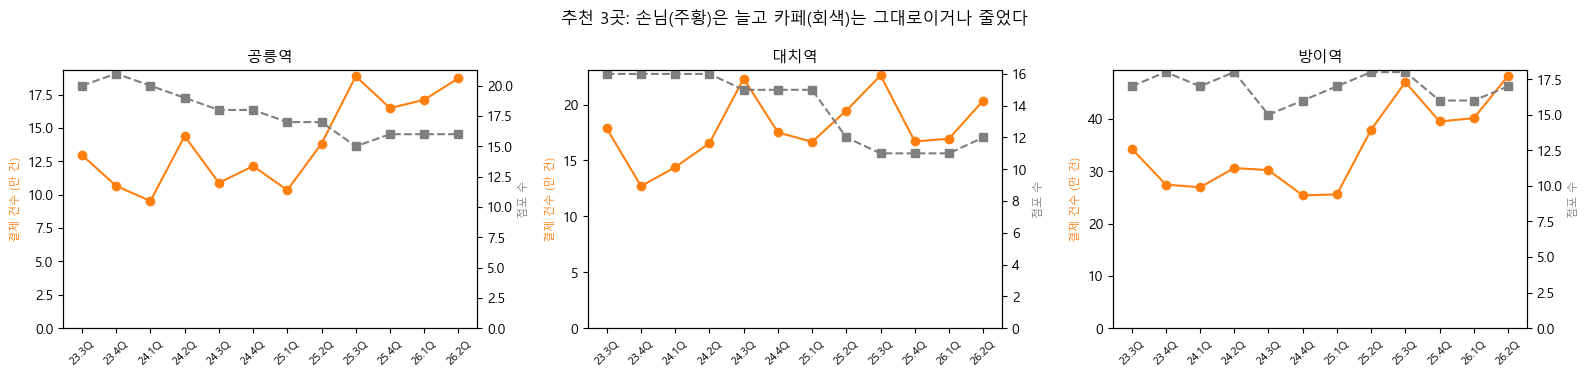

In [22]:
x_labels = [quarter_label(q) for q in quarters_12]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, code in zip(axes, final_codes):
    ax.plot(x_labels, count_pivot.loc[code] / 1e4, marker="o", color="tab:orange")
    ax.set_ylim(bottom=0)
    ax.set_ylabel("결제 건수 (만 건)", color="tab:orange", fontsize=8)

    ax_store = ax.twinx()  # 건수와 점포 수는 단위가 달라 보조 축 사용
    ax_store.plot(x_labels, store_pivot.loc[code], marker="s", linestyle="--", color="tab:gray")
    ax_store.set_ylim(bottom=0)
    ax_store.set_ylabel("점포 수", color="tab:gray", fontsize=8)

    ax.set_title(code_to_name[code], fontsize=11)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)

plt.suptitle("추천 3곳: 손님(주황)은 늘고 카페(회색)는 그대로이거나 줄었다")
plt.tight_layout()
plt.show()

### 관찰
- 결제 건수는 세 곳 모두 2025년 1분기 → 3분기 상승: 공릉역 10.3만 → 18.9만, 대치역 16.7만 → 22.6만, 방이역 25.6만 → 47.1만 건
- 같은 기간 점포 수는 공릉역 17 → 15개, 대치역 15 → 11개, 방이역 17 → 18개 → 카페 한 곳이 받는 손님 증가 확인
- 분기별 등락이 커서 한 분기 값보다 4개 분기 합계 기준 비교가 필요하다는 `01` 결론과 일치

## 6. 결과 저장

- 순위 표는 최종 보고 덱과 `05_예측`에서 사용

In [23]:
save_cols = ["순위", "일대", "상권_코드_명", "상권_구분_코드_명", "자치구_코드_명", "점포_2년전", "점포_최근",
             "손님_2년_증가율", "점포_2년_증가율", "점포당_손님_2년_증가율", "전년동기_상승_분기_수", "건당_금액_2년_변화율",
             "점포당_월_손님", "점포당_월_매출", "성장", "손님_여력", "수익성", "점수", "엑스좌표_값", "와이좌표_값"]

ranking_output = clustered.assign(추천=lambda d: d.index.isin(final_codes))
ranking_output[save_cols + ["추천"]].round(2).to_csv(OUT_DIR / "추천_순위.csv", encoding="utf-8")
funnel.to_csv(OUT_DIR / "추천_깔때기.csv", index=False, encoding="utf-8")
cluster_rent_selected.round(2).to_csv(OUT_DIR / "추천_임대료.csv", encoding="utf-8")
print(len(ranking_output), "행 저장, 추천 대표 상권:", final_codes)

84 행 저장, 추천 대표 상권: ['3120084', '3120220', '3120238']


## 결론과 다음 단계

- 992개 상권 → 6단계 거르기 → 84개 → 1km 일대 → 임대료·2km 조건 → 추천 3곳
- **추천: 공릉역(노원구), 대치역(강남구), 방이역(송파구)**
  - 점포당 손님 2년 증가율 +90.2%, +77.1%, +53.2%
  - 카페 수 2년 증가율 −21.2%, −29.7%, −4.3%
- 한계
  - 세 곳 모두 1.5km 안에 임대료 조사 상권 없음 → 실제 매물 임대료·권리금 확인 필요
  - 결과를 보고 추가한 규칙 2개(데이터 단절 제외, 추천 3곳 사이 2km)
- 다음 단계: `05_예측.ipynb`에서 추천 3곳의 다음 1년 매출·손님 예측